In [1]:
import pymc as pm
import numpy as np
import matplotlib.pyplot as plt
import arviz as az

### Eight Schools case

In [2]:
y  = [28, 8, -3, 7, -1, 1, 18, 12]
sigma = [15, 10, 16, 11, 9, 11, 10, 18]

In [3]:
model = pm.Model()

with model:

    mu = pm.Normal("mu", mu=0, sigma=5)
    tau = pm.HalfCauchy("tau", beta=5)

    # theta = pm.Normal("theta", mu=mu, sigma=tau, shape=len(y))

    z = pm.Normal("z", 0, 1, shape=len(y))
    theta = pm.Deterministic("theta", mu + tau * z)

    y_obs = pm.Normal("y_obs", mu=theta, sigma=sigma, observed=y)

    # step = pm.NUTS()
    step = pm.Metropolis()
    # step = pm.HamiltonianMC()
    idata = pm.sample(draws=2000, 
                      tune=1000, 
                      chains=4,
                      step=step, 
                      random_seed=42)
    pm.sample_posterior_predictive(idata, extend_inferencedata=True, random_seed=42)

    approx   = pm.fit(n=30_000, method="advi", random_seed=42)
    idata_vi = approx.sample(8000, random_seed=42)


Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [mu]
>Metropolis: [tau]
>Metropolis: [z]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 15 seconds.
Sampling: [y_obs]


Output()

Output()

Finished [100%]: Average Loss = 31.938


In [4]:
print(az.summary(idata, var_names=["mu", "tau", "theta"], round_to=2))

          mean    sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  \
mu        4.38  3.43     -1.16      9.90   1384.53   1629.03   1.00   
tau       3.79  3.29      0.29     10.12    912.24   1328.37   1.01   
theta[0]  6.33  5.87     -1.48     16.66   1357.41   2042.55   1.00   
theta[1]  5.05  4.90     -2.29     12.89   1946.71   2475.79   1.00   
theta[2]  3.89  5.45     -4.75     11.87   1706.30   2123.58   1.00   
theta[3]  4.85  4.94     -2.72     12.76   1928.82   2500.62   1.00   
theta[4]  3.44  4.97     -4.73     10.72   1997.37   2723.10   1.00   
theta[5]  4.12  5.09     -3.87     11.81   2099.28   2567.68   1.00   
theta[6]  6.50  5.23     -0.57     15.57   1872.85   2295.15   1.00   
theta[7]  4.83  5.60     -3.19     13.66   2024.56   2457.33   1.00   

          mcse_mean  mcse_sd  
mu             0.09     0.06  
tau            0.10     0.10  
theta[0]       0.16     0.13  
theta[1]       0.11     0.10  
theta[2]       0.13     0.12  
theta[3]       0.11     0.09  
t

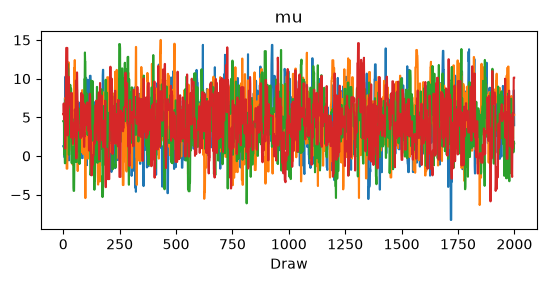

In [5]:
az.plot_trace(idata, var_names=["mu"])
plt.show()

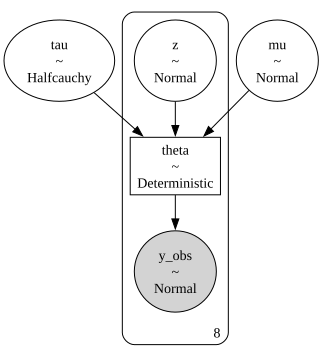

In [6]:
pm.model_to_graphviz(model)

In [7]:
idata.posterior_predictive

<xarray.DataTree 'posterior_predictive'>
Group: /posterior_predictive
    Dimensions:      (chain: 4, draw: 2000, y_obs_dim_0: 8)
    Coordinates:
      * chain        (chain) int64 32B 0 1 2 3
      * draw         (draw) int64 16kB 0 1 2 3 4 5 ... 1994 1995 1996 1997 1998 1999
      * y_obs_dim_0  (y_obs_dim_0) int64 64B 0 1 2 3 4 5 6 7
    Data variables:
        y_obs        (chain, draw, y_obs_dim_0) float64 512kB 8.716 3.442 ... 21.28
    Attributes:
        created_at:                 2026-11-14T15:19:54.677905+00:00
        creation_library:           ArviZ
        creation_library_version:   1.3.1
        creation_library_language:  Python
        inference_library:          pymc
        inference_library_version:  6.3.2
        sample_dims:                ['chain', 'draw']

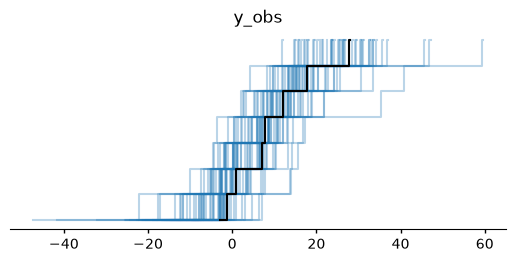

In [8]:
az.plot_ppc_dist(idata)

In [12]:
y_arr, s_arr = np.array(y), np.array(sigma)

with pm.Model() as pooled:
    mu = pm.Normal("mu", 0, 10)
    pm.Normal("y_obs", mu=mu, sigma=s_arr, observed=y_arr)
    idata_pooled = pm.sample(2000, tune=1000, idata_kwargs={"log_likelihood": True})

with pm.Model() as unpooled:
    theta = pm.Normal("theta", 0, 20, shape=8)
    pm.Normal("y_obs", mu=theta, sigma=s_arr, observed=y_arr)
    idata_unpooled = pm.sample(2000, tune=1000, idata_kwargs={"log_likelihood": True})

with model:                         
    pm.compute_log_likelihood(idata)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu]


Output()

Output()

Output()

In [13]:
az.compare({"pooled": idata_pooled, "unpooled": idata_unpooled, "hierarchical": idata})

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
pooled,0,0.0,0.00,NaN,,,0.6,-30.0,1.30,1.0
hierarchical,1,-0.3,0.32,0.84,N < 100,,0.9,-31.0,1.40,0.0
unpooled,2,-3.0,0.72,1.00,N < 100,3 k̂ > 0.70,3.6,-33.0,0.61,0.0


In [49]:
# ---- Compare ----
print("NUTS:")
print(az.summary(idata, var_names=["mu", "tau"], kind="stats"))
print("\nADVI:")
print(az.summary(idata_vi, var_names=["mu", "tau"], kind="stats"))

NUTS:
    mean   sd eti89_lb eti89_ub
mu   6.6    4     0.15       13
tau  3.6  3.2     0.27      9.5

ADVI:
    mean   sd eti89_lb eti89_ub
mu   5.5  3.8    -0.76       12
tau  3.5  4.1     0.47       10
